# Панель ключевых показателей (прототип)

Панель пересчитывается после обработки каждой порции: `python -m src.pipeline all`.

Сейчас показаны показатели, которые не требуют модели (Таблица 2.5 отчета): число заявок, средняя сумма кредита, доля записей, не прошедших проверку. Показатели на основе модели (доля заявок в зоне риска, ожидаемые потери) добавляются после обучения модели в ПР3.

Фактическая доля дефолтов в реальной системе становится известна позже; в учебных порциях метка есть, поэтому показатель приведен для контроля.

In [1]:
import json, os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e4e3df', 'axes.axisbelow': True, 'figure.dpi': 110})
COLOR, MUTED = '#2a78d6', '#52514e'

## Показатели по порциям

In [2]:
rows = []
for f in sorted(Path('data/reports').glob('batch_*_quality.json')):
    r = json.loads(f.read_text(encoding='utf-8'))
    raw = pd.read_csv(Path('data/incoming') / r['file'])
    rows.append({
        'порция': r['file'].replace('.csv', ''),
        'статус': r['status'],
        'записей в порции': r['rows_in'],
        'заявок после проверки': r['kpi']['applications'],
        'доля исключенных, %': round(100 * r['rejected_share'], 2),
        'средняя сумма кредита': r['kpi']['mean_loan_amnt'],
        'пропуски ставки, %': round(100 * r['int_rate_missing_share'], 1),
        'факт. доля дефолтов, %': round(100 * raw['loan_status'].mean(), 1),
    })
kpi = pd.DataFrame(rows).set_index('порция')
kpi

,статус,записей в порции,заявок после проверки,"доля исключенных, %",средняя сумма кредита,"пропуски ставки, %","факт. доля дефолтов, %"
порция,,,,,,,
batch_01,ok,3258,3213,1.38,9424.16,9.8,22.3
batch_02,ok,3258,3213,1.38,9456.63,9.2,21.8
batch_03,ok,3258,3219,1.20,9486.66,9.4,21.6
batch_04,ok,3258,3227,0.95,9445.35,10.2,20.1


## Динамика показателей

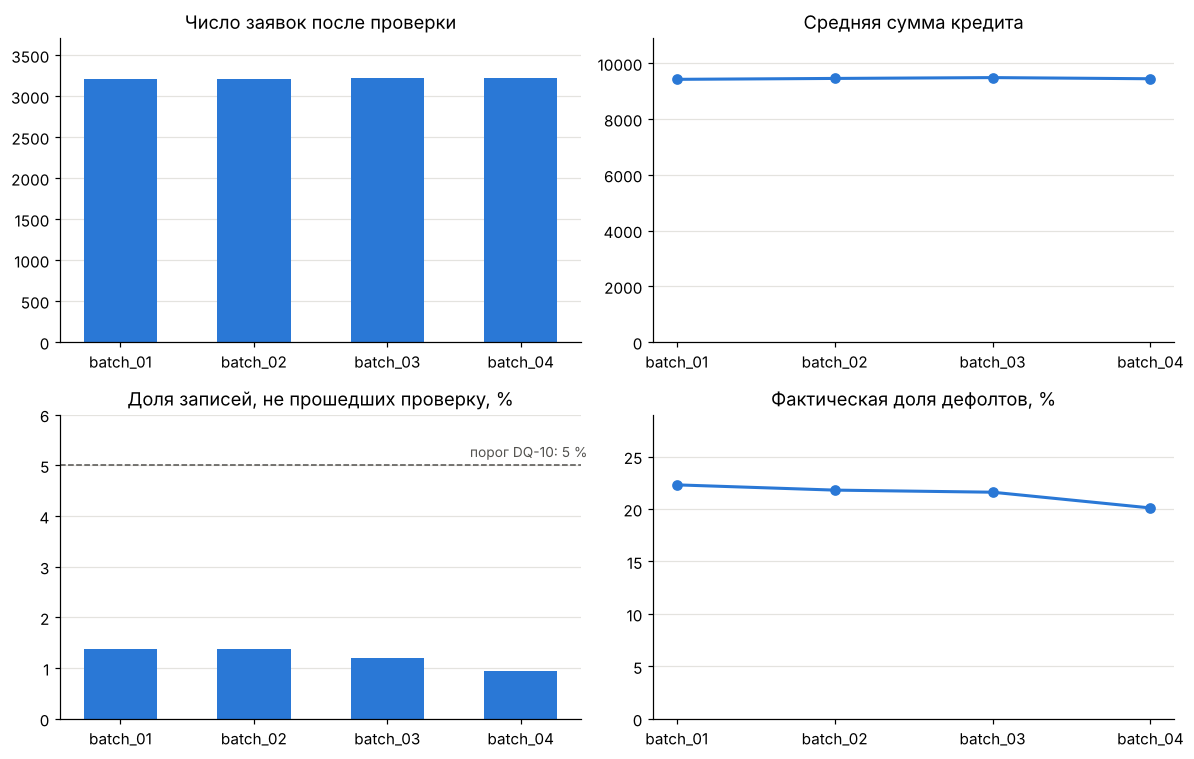

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
x = kpi.index

ax = axes[0, 0]
ax.bar(x, kpi['заявок после проверки'], color=COLOR, width=0.55)
ax.set_title('Число заявок после проверки')
ax.set_ylim(0, kpi['заявок после проверки'].max() * 1.15)

ax = axes[0, 1]
ax.plot(x, kpi['средняя сумма кредита'], marker='o', color=COLOR, lw=2)
ax.set_title('Средняя сумма кредита')
ax.set_ylim(0, kpi['средняя сумма кредита'].max() * 1.15)

ax = axes[1, 0]
ax.bar(x, kpi['доля исключенных, %'], color=COLOR, width=0.55)
ax.axhline(5, color=MUTED, ls='--', lw=1)
ax.text(len(x) - 0.5, 5.1, 'порог DQ-10: 5 %', ha='right', va='bottom', color=MUTED, fontsize=9)
ax.set_title('Доля записей, не прошедших проверку, %')
ax.set_ylim(0, 6)

ax = axes[1, 1]
ax.plot(x, kpi['факт. доля дефолтов, %'], marker='o', color=COLOR, lw=2)
ax.set_title('Фактическая доля дефолтов, %')
ax.set_ylim(0, kpi['факт. доля дефолтов, %'].max() * 1.3)

for ax in axes.ravel():
    ax.grid(axis='x', visible=False)
fig.tight_layout()
fig.savefig('reports/figures/fig_dashboard.png', bbox_inches='tight', dpi=150)   # рисунок для отчета
plt.show()

## Состояние последней порции

In [4]:
last = kpi.iloc[-1]
print(f"Порция: {kpi.index[-1]}, статус проверки: {last['статус']}")
print(f"Заявок: {last['заявок после проверки']}, исключено: {last['доля исключенных, %']} %")
if last['доля исключенных, %'] > 5:
    print('Внимание: превышен порог DQ-10, порция требует ручной проверки')

Порция: batch_04, статус проверки: ok
Заявок: 3227, исключено: 0.95 %
